# Keşif

In [1]:
import numpy as np
import pandas as pd
%load_ext autoreload
%autoreload 2
import os

In [2]:
from olist.data import Olist
import inspect

print(inspect.getfile(Olist))

C:\Users\USER\workintech\sprint-15\olist\data.py


In [2]:
import os
import inspect
from olist.data import Olist

print("PYTHONPATH:", os.environ.get("PYTHONPATH"))
print("Olist dosyası:", inspect.getfile(Olist))

PYTHONPATH: C:\Users\USER\workintech\sprint-15;C:\Users\USER\workintech\sprint-15
Olist dosyası: C:\Users\USER\workintech\sprint-15\olist\data.py


## Veriyi Al

In [3]:
from olist.data import Olist
data = Olist().get_data()

Olist e-ticaret platformundaki her işlem şu özelliklere sahiptir:
- satın alacak olan bir `customer_id`...
- çeşitli `product_id`...
- bir `seller_id`...
- ve bir `review_id`...
- tüm bunlar bir `order_id`'ye aittir.

## Çeşitli DataFrame'lerinizin kardinalitelerini araştırın

❓ **Kaç tane benzersiz `orders`, `reviews`, `sellers`, `products` and `customers` var ?**

In [4]:
print("Benzersiz sipariş:", data["orders"]["order_id"].nunique())
print("Benzersiz yorum:", data["order_reviews"]["review_id"].nunique())
print("Benzersiz satıcı:", data["sellers"]["seller_id"].nunique())
print("Benzersiz ürün:", data["products"]["product_id"].nunique())
print("Benzersiz müşteri:", data["customers"]["customer_id"].nunique())

Benzersiz sipariş: 99441
Benzersiz yorum: 98410
Benzersiz satıcı: 3095
Benzersiz ürün: 32951
Benzersiz müşteri: 99441


❓ **Sipariş başına kaç tane yorum(reviews) var? Tüm siparişler için yorum var mı?**
<details>
    <summary markdown=‘span’>İpuçları</summary>

Bu bilgiye bireysel csv dosyanızdan doğrudan erişemezsiniz. Öğrenmek için tabloları birleştirmeniz gerekir. Hangi tür birleştirme yapmanız gerektiğini düşünün.

Hangi tablolara ihtiyacınız olduğundan emin değil misiniz? Öğrenmek için ERD'nize geri dönün.

Yorum sayısını öğrenmek için: `order_id` başına yorum sayısını sayın ve bir histogram çizin. Pandas serisinde `.hist()` kullanabilirsiniz.
</details>

In [6]:
%pip install matplotlib

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ------ --------------------------------- 1.6/9.3 MB 10.5 MB/s eta 0:00:01
   -------------------------- ------------- 6.3/9.3 MB 18.4 MB/s eta 0:00:01
   ----------------------------------- ---- 8.4/9.3 MB 14.9 MB/s eta 0:00:01
   ---------------------------------------- 9.3/9.3 MB 12.4 MB/s eta 0:00:00
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 2.5/2.5 MB 28.5 MB/s eta 0:00:00
   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
   ----------- ---------------------------- 3.7/12.6 MB 36.6 MB/s eta 0:00:01
   -------------------------------- ------- 10.2/12.6 MB 24.5 MB/s eta 0:00:01
   ---------------------------------------- 12.6/12.6 MB 20.8 MB/s eta 0:00:00
   ---------------------------------------- 0.0/7.2 MB

  You can safely remove it manually.
  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tensorflow-intel 2.17.0 requires numpy<2.0.0,>=1.26.0; python_version >= "3.12", but you have numpy 2.5.4 which is incompatible.
tensorflow-intel 2.17.0 requires protobuf!=4.21.0,!=4.21.1,!=4.21.2,!=4.21.3,!=4.21.4,!=4.21.5,<5.0.0dev,>=3.20.3, but you have protobuf 6.33.6 which is incompatible.

[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
import matplotlib.pyplot as plt
print("Matplotlib çalışıyor!")

Matplotlib çalışıyor!


<Axes: >

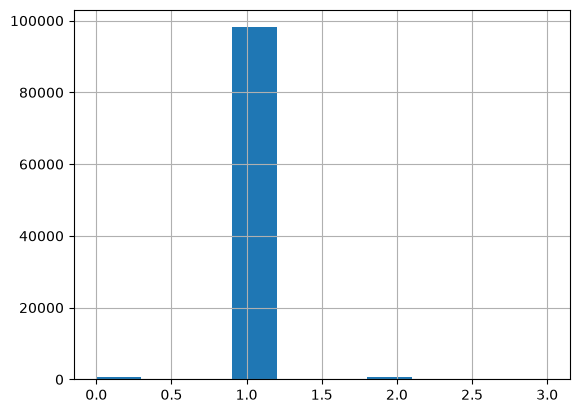

In [6]:
orders_reviews = data["orders"][["order_id"]].merge(
    data["order_reviews"][["order_id", "review_id"]],
    on="order_id",
    how="left"
)

reviews_per_order = orders_reviews.groupby("order_id")["review_id"].count()

reviews_per_order.hist()

🧪 **Test your code below**

Yorum eksik olan siparişlerin sayısını `int` olarak `n_missing_reviews` adlı bir değişkende saklayın.

In [7]:
n_missing_reviews = int((reviews_per_order == 0).sum())
n_missing_reviews

768

In [8]:
from nbresult import ChallengeResult

result = ChallengeResult('exploratory',
    n=n_missing_reviews
)
result.write()
print(result.check())


============================= test session starts =============================
platform win32 -- Python 3.12.6, pytest-9.1.1, pluggy-1.6.0 -- c:\Users\USER\AppData\Local\Programs\Python\Python312\python.exe
cachedir: .pytest_cache
rootdir: c:\Users\USER\workintech\sprint-15\data-exploratory-analysis\tests
plugins: anyio-4.15.1
collecting ... collected 1 item

test_exploratory.py::TestExploratory::test_n_missing_reviews PASSED      [100%]

============================== 1 passed in 0.07s ==============================


💯 You can commit your code:

git add tests/exploratory.pickle

git commit -m 'Completed exploratory step'

git push origin master

